PHISHING DETECTION - PIPELINE WITH LIGHTGBM
Dimensions du dataset: 11430 lignes × 89 colonnes
Aperçu des 5 premières lignes du dataset:
                                                 url  length_url  \
0              http://www.crestonwood.com/router.php          37   
1  http://shadetreetechnology.com/V4/validation/a...          77   
2  https://support-appleld.com.secureupdate.duila...         126   
3                                 http://rgipt.ac.in          18   
4  http://www.iracing.com/tracks/gateway-motorspo...          55   

   length_hostname  ip  nb_dots  nb_hyphens  nb_at  nb_qm  nb_and  nb_or  ...  \
0               19   0        3           0      0      0       0      0  ...   
1               23   1        1           0      0      0       0      0  ...   
2               50   1        4           1      0      1       2      0  ...   
3               11   0        2           0      0      0       0      0  ...   
4               15   0        2           2      0

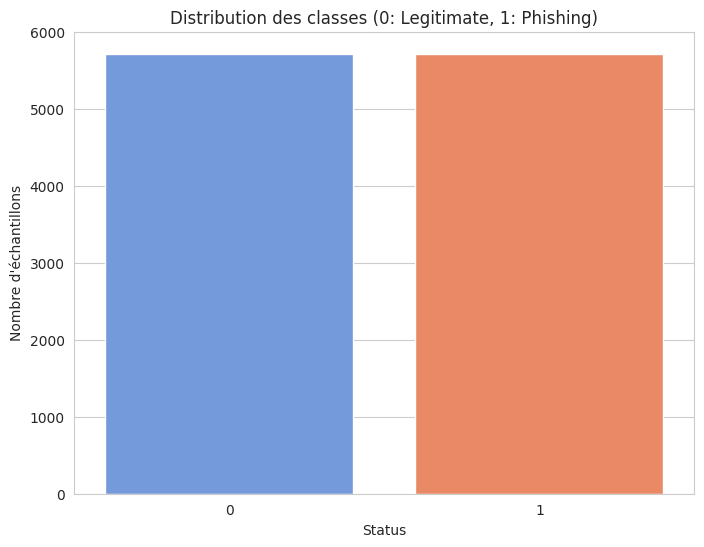


Nombre de caractéristiques initiales: 87
Aperçu des noms de colonnes utilisées comme features:
['length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and', 'nb_or', 'nb_eq', 'nb_underscore', 'nb_tilde', 'nb_percent', 'nb_slash', 'nb_star', 'nb_colon', 'nb_comma', 'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_www', 'nb_com', 'nb_dslash', 'http_in_path', 'https_token', 'ratio_digits_url', 'ratio_digits_host', 'punycode', 'port', 'tld_in_path', 'tld_in_subdomain', 'abnormal_subdomain', 'nb_subdomains', 'prefix_suffix', 'random_domain', 'shortening_service', 'path_extension', 'nb_redirection', 'nb_external_redirection', 'length_words_raw', 'char_repeat', 'shortest_words_raw', 'shortest_word_host', 'shortest_word_path', 'longest_words_raw', 'longest_word_host', 'longest_word_path', 'avg_words_raw', 'avg_word_host', 'avg_word_path', 'phish_hints', 'domain_in_brand', 'brand_in_subdomain', 'brand_in_path', 'suspecious_tld', 'statistical_report', 'nb_hyperlinks'

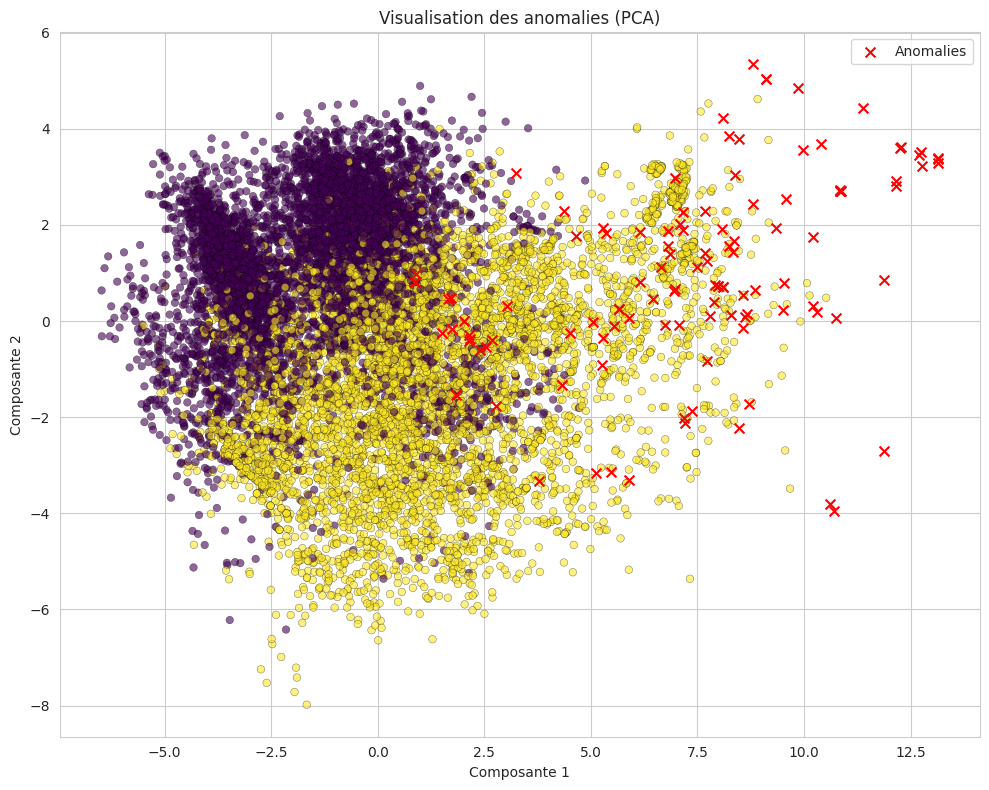


Rééquilibrage des classes avec SMOTE...
Distribution des classes après SMOTE: [5709 5709]


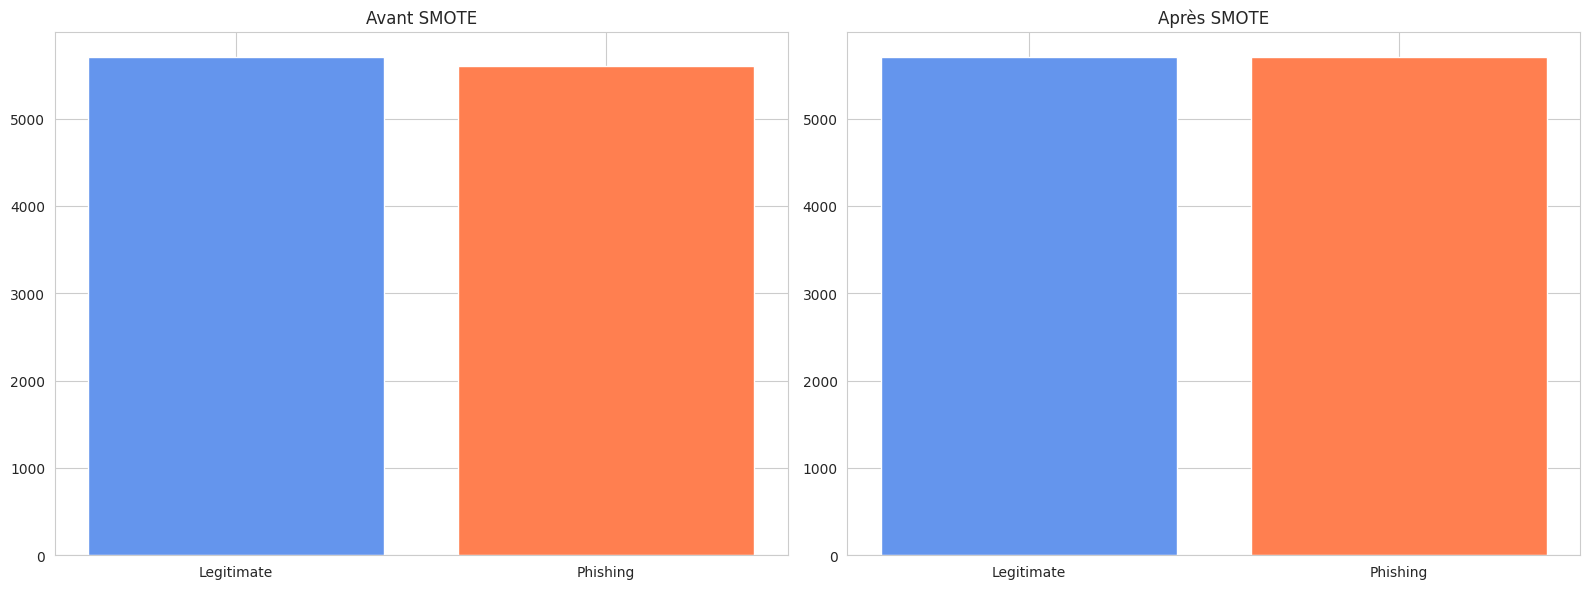


Sélection des features avec RFECV...
Fitting estimator with 87 features.
[LightGBM] [Info] Number of positive: 5709, number of negative: 5709
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005735 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 5214
[LightGBM] [Info] Number of data points in the train set: 11418, number of used features: 73
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
Fitting estimator with 86 features.
[LightGBM] [Info] Number of positive: 5709, number of negative: 5709
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006713 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 5201
[LightGBM] [Info] Number of data points in the train set: 11

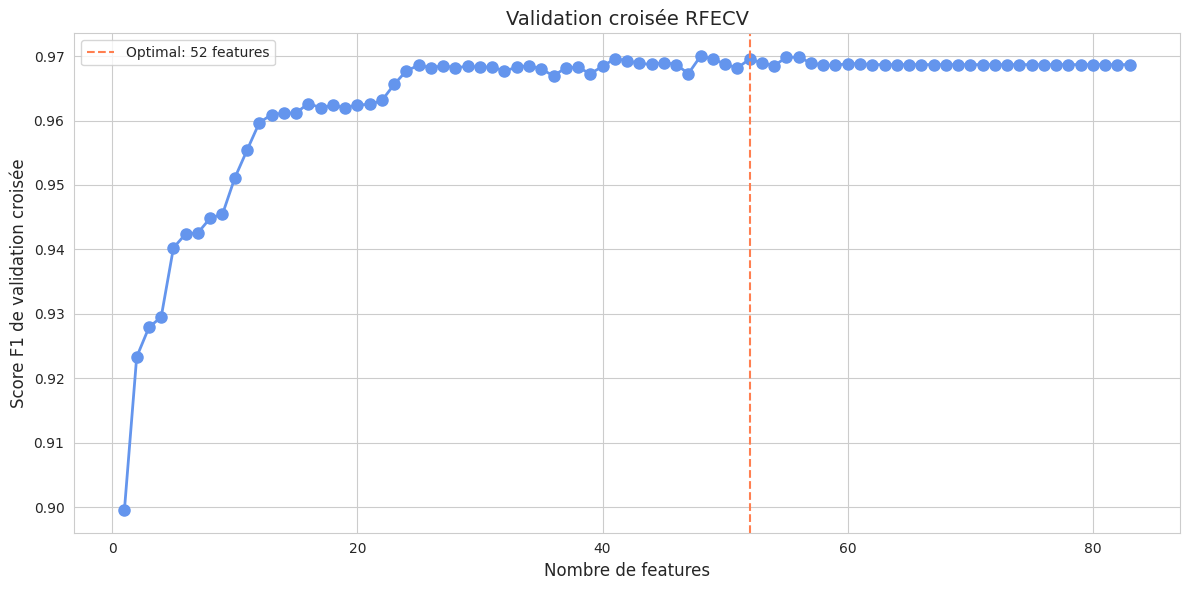


Features sélectionnées par RFECV:
1. length_url
2. length_hostname
3. nb_dots
4. nb_hyphens
5. nb_at
6. nb_qm
7. nb_eq
8. nb_underscore
9. nb_percent
10. nb_slash
11. nb_space
12. nb_www
13. https_token
14. ratio_digits_url
15. ratio_digits_host
16. tld_in_subdomain
17. shortening_service
18. nb_redirection
19. length_words_raw
20. char_repeat
21. shortest_words_raw
22. shortest_word_host
23. shortest_word_path
24. longest_words_raw
25. longest_word_host
26. longest_word_path
27. avg_words_raw
28. avg_word_host
29. avg_word_path
30. phish_hints
31. domain_in_brand
32. statistical_report
33. nb_hyperlinks
34. ratio_intHyperlinks
35. ratio_extHyperlinks
36. nb_extCSS
37. ratio_extRedirection
38. ratio_extErrors
39. login_form
40. external_favicon
41. links_in_tags
42. ratio_intMedia
43. ratio_extMedia
44. safe_anchor
45. empty_title
46. domain_in_title
47. domain_with_copyright
48. domain_registration_length
49. domain_age
50. web_traffic
51. google_index
52. page_rank


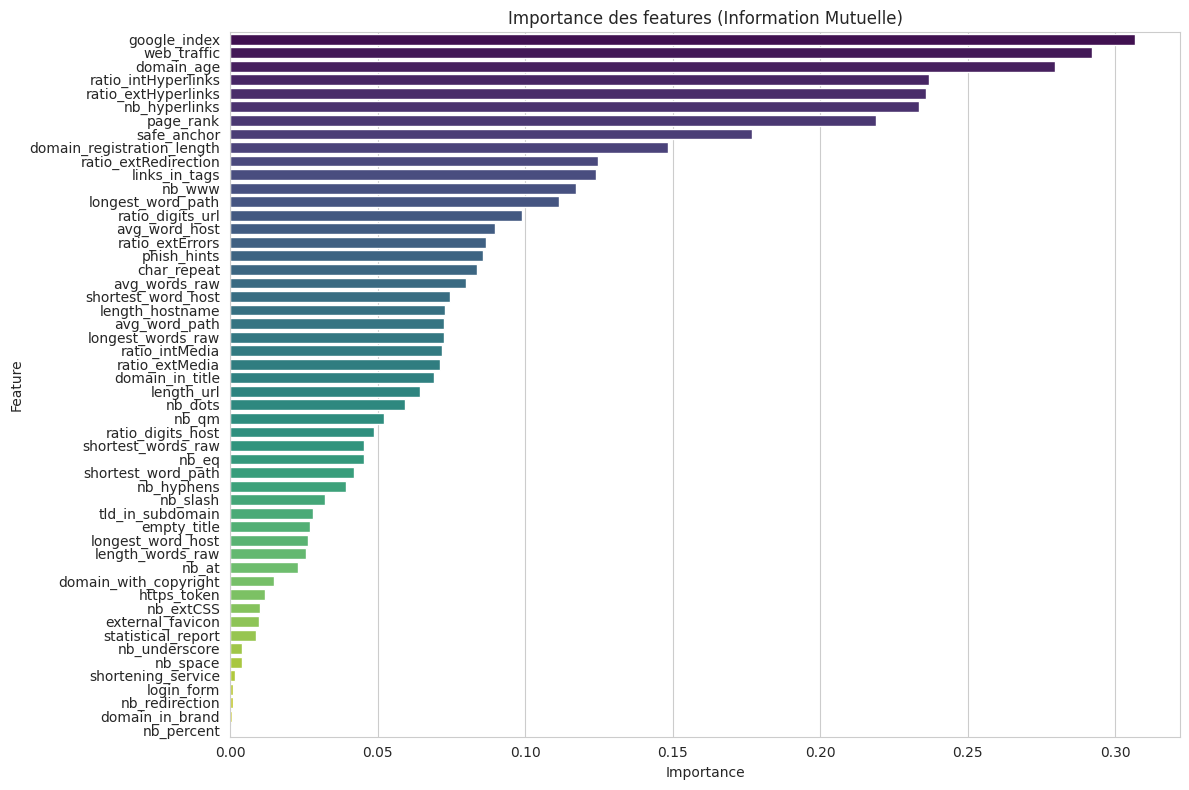


Séparation des données en ensembles d'entraînement et de test...
Train set: (9134, 52), Test set: (2284, 52)

Recherche d'hyperparamètres pour LightGBM...
Fitting 5 folds for each of 729 candidates, totalling 3645 fits
[LightGBM] [Info] Number of positive: 4567, number of negative: 4567
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004589 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4998
[LightGBM] [Info] Number of data points in the train set: 9134, number of used features: 52
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
Meilleurs paramètres: {'learning_rate': 0.1, 'min_child_samples': 50, 'n_estimators': 200, 'num_leaves': 75, 'reg_alpha': 0, 'reg_lambda': 0}
Meilleur score de validation: 0.9700

Entraînement final du modèle LightGBM...
Training until validation scores don't improve for 50 round

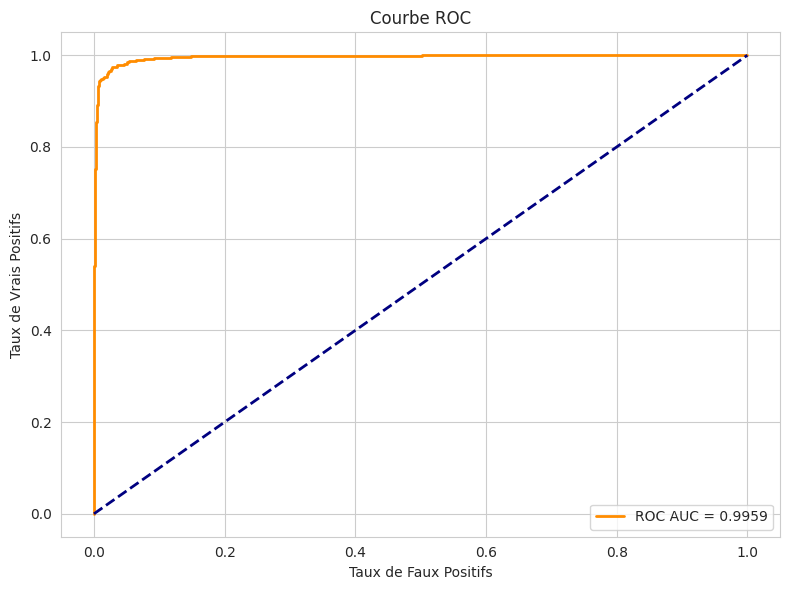

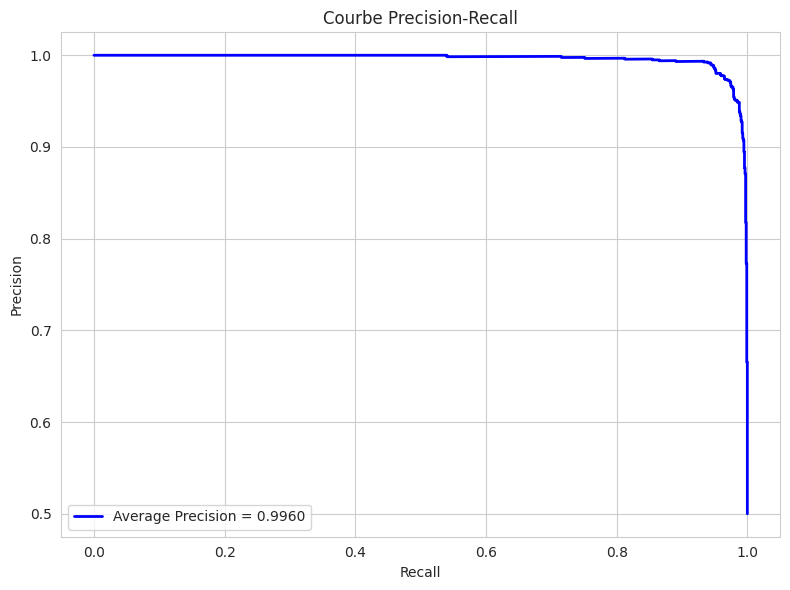

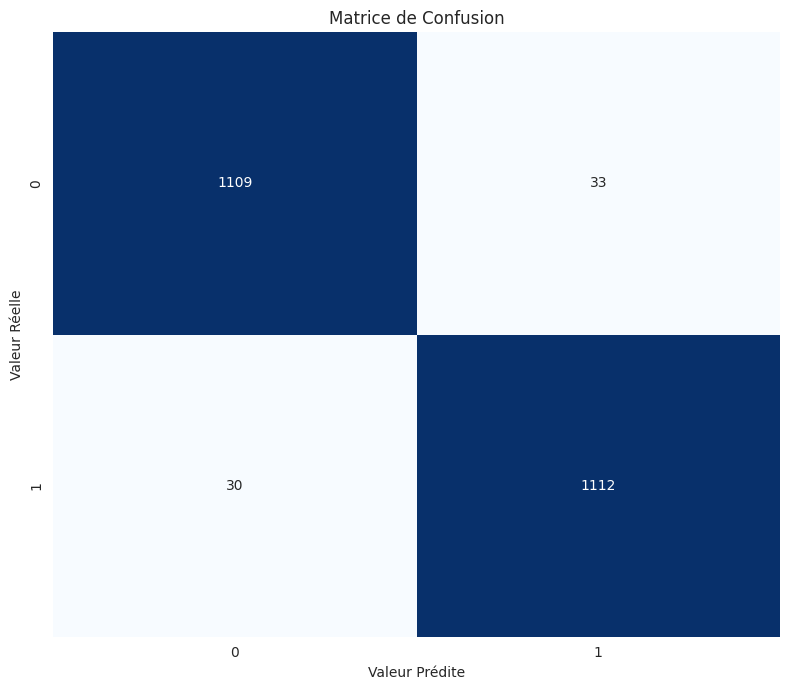

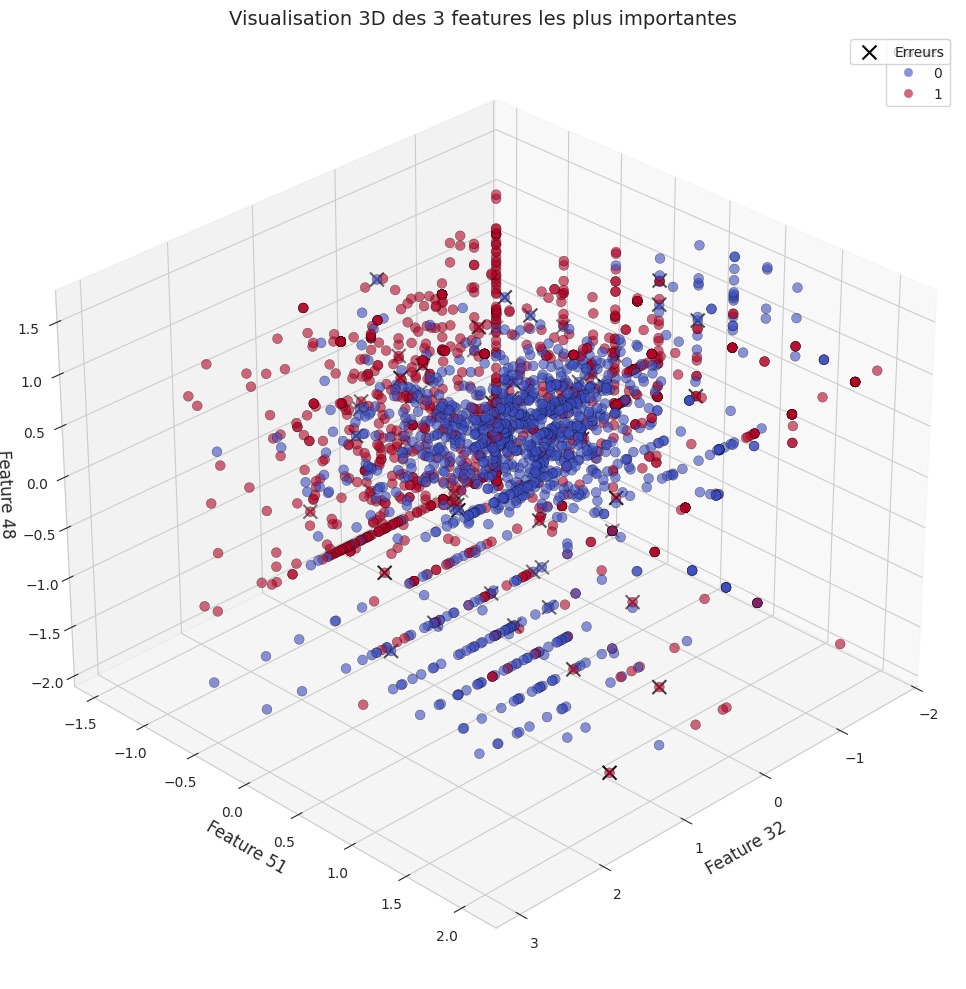


Sauvegarde du modèle LightGBM final...
Modèle sauvegardé sous 'lightgbm_phishing_model.txt'

PIPELINE TERMINÉE


In [ ]:
# -*- coding: utf-8 -*-
"""
PHISHING DETECTION PIPELINE USING LIGHTGBM
==========================================
This script loads the dataset "dataset_phishing.csv", performs exploratory analysis,
preprocessing (including scaling, anomaly removal, and rebalancing), selects features,
tunes hyperparameters, trains a LightGBM model, and finally evaluates and saves the model.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import warnings
warnings.filterwarnings('ignore')

# ---------------------------
# 1. Importation des librairies complémentaires
# ---------------------------
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, learning_curve
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.metrics import classification_report, roc_curve, auc, accuracy_score, precision_recall_curve
from sklearn.metrics import confusion_matrix, average_precision_score, f1_score
from sklearn.feature_selection import RFECV, mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from imblearn.over_sampling import SMOTE

# Global display settings
np.set_printoptions(precision=4)
pd.set_option('display.precision', 4)
sns.set_style('whitegrid')
plt.style.use('seaborn-v0_8-pastel')

# ---------------------------
# 2. Chargement et exploration du dataset
# ---------------------------
print("="*80)
print("PHISHING DETECTION - PIPELINE WITH LIGHTGBM")
print("="*80)

# Chargement du dataset (assure-toi que le fichier est au bon endroit)
dataset_path = "dataset_phishing.csv"
df = pd.read_csv(dataset_path)

print(f"Dimensions du dataset: {df.shape[0]} lignes × {df.shape[1]} colonnes")
print("Aperçu des 5 premières lignes du dataset:")
print(df.head())

# ------------ Prétraitement de la target ------------
# Nous supposons que la colonne 'status' est la variable cible et
# contient 'legitimate' et 'phishing' en valeurs.
if 'status' in df.columns:
    df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})
else:
    raise ValueError("La colonne 'status' est absente du dataset.")

# Supprimer les observations dont la target est manquante
df.dropna(subset=['status'], inplace=True)

# ------------ Exploration rapide ------------
plt.figure(figsize=(8,6))
sns.countplot(x='status', data=df, palette=['#6495ED','#FF7F50'])
plt.title('Distribution des classes (0: Legitimate, 1: Phishing)')
plt.xlabel('Status')
plt.ylabel("Nombre d'échantillons")
plt.show()

# ---------------------------
# 3. Préparation des features
# ---------------------------
# On supprime la colonne 'url' car elle n'est pas utilisée directement dans le modèle
if 'url' in df.columns:
    df.drop(columns=['url'], inplace=True)

# Séparation des variables explicatives et de la cible
X = df.drop(columns=['status'])
y = df['status']

print(f"\nNombre de caractéristiques initiales: {X.shape[1]}")
print("Aperçu des noms de colonnes utilisées comme features:")
print(X.columns.tolist())

# ---------------------------
# 4. Transformation & Scaling
# ---------------------------
print("\nApplication de transformations pour normaliser les distributions...")

# D'abord, transformation de puissance pour stabiliser la variance (Yeo-Johnson fonctionne avec des valeurs négatives)
power_transformer = PowerTransformer(method='yeo-johnson')
X_transformed = power_transformer.fit_transform(X)

# Puis standardisation (centrage et réduction)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_transformed)

print("Transformations appliquées.")

# ---------------------------
# 5. Détection et suppression des anomalies avec IsolationForest
# ---------------------------
print("\nDétection des anomalies avec IsolationForest...")
# Ici, on choisit une contamination de 1% (adapter selon le dataset)
chosen_contamination = 0.01
iso = IsolationForest(contamination=chosen_contamination, random_state=42, n_jobs=-1)
pred_anomalies = iso.fit_predict(X_scaled)
mask = pred_anomalies != -1  # On garde seulement les points normaux
X_clean = X_scaled[mask]
y_clean = y[mask]

nombre_anomalies = len(X_scaled) - np.sum(mask)
print(f"Points supprimés comme anomalies: {nombre_anomalies} ({nombre_anomalies/len(X_scaled)*100:.2f}%)")

# Visualisation rapide des anomalies (projection PCA en 2D)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10,8))
plt.scatter(X_pca[mask, 0], X_pca[mask, 1], c=y[mask], cmap='viridis', alpha=0.6, s=30, edgecolor='k', linewidth=0.3)
plt.scatter(X_pca[~mask, 0], X_pca[~mask, 1], c='red', marker='x', s=50, label='Anomalies')
plt.title("Visualisation des anomalies (PCA)")
plt.xlabel("Composante 1")
plt.ylabel("Composante 2")
plt.legend()
plt.tight_layout()
plt.show()

# ---------------------------
# 6. Rééquilibrage avec SMOTE
# ---------------------------
print("\nRééquilibrage des classes avec SMOTE...")
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_clean, y_clean)
print(f"Distribution des classes après SMOTE: {np.bincount(y_res)}")

# Visualisation de la distribution avant/après SMOTE
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
ax1.bar(['Legitimate', 'Phishing'], [np.sum(y_clean==0), np.sum(y_clean==1)], color=['#6495ED','#FF7F50'])
ax1.set_title("Avant SMOTE")
ax2.bar(['Legitimate', 'Phishing'], [np.sum(y_res==0), np.sum(y_res==1)], color=['#6495ED','#FF7F50'])
ax2.set_title("Après SMOTE")
plt.tight_layout()
plt.show()

# ---------------------------
# 7. Sélection de caractéristiques avec RFECV
# ---------------------------
print("\nSélection des features avec RFECV...")
# Utilisation du modèle LightGBM comme estimateur de base
base_lgbm = lgb.LGBMClassifier(random_state=42, n_jobs=-1)

# RFECV avec une validation croisée en stratification et la métrique F1
rfecv = RFECV(estimator=base_lgbm,
              step=1,
              cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
              scoring='f1',
              n_jobs=-1,
              verbose=1,
              min_features_to_select=5)

rfecv.fit(X_res, y_res)
print(f"Nombre optimal de features: {rfecv.n_features_}")

# Pour certaines versions de scikit-learn, les scores se trouvent dans cv_results_['mean_test_score']
if hasattr(rfecv, "cv_results_['mean_test_score']"):
    print(f"Score avec {rfecv.n_features_} features: {rfecv.cv_results_['mean_test_score'][rfecv.n_features_-1]:.4f}")

# Visualisation des scores RFECV
plt.figure(figsize=(12,6))
plt.plot(range(1, len(rfecv.cv_results_['mean_test_score'])+1), rfecv.cv_results_['mean_test_score'], marker='o', color='#6495ED',
         linestyle='-', linewidth=2, markersize=8)
plt.axvline(x=rfecv.n_features_, color='#FF7F50', linestyle='--', label=f'Optimal: {rfecv.n_features_} features')
plt.xlabel("Nombre de features", fontsize=12)
plt.ylabel("Score F1 de validation croisée", fontsize=12)
plt.title("Validation croisée RFECV", fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

selected_features_mask = rfecv.support_
selected_feature_names = X.columns[selected_features_mask]
print("\nFeatures sélectionnées par RFECV:")
for i, feat in enumerate(selected_feature_names):
    print(f"{i+1}. {feat}")

# On ne garde que les features sélectionnées
X_selected = rfecv.transform(X_res)

# ---------------------------
# 8. Analyse de l'importance des features (Mutual Information)
# ---------------------------
mi_scores = mutual_info_classif(X_selected, y_res, random_state=42)
mi_df = pd.DataFrame({'Feature': selected_feature_names, 'Importance': mi_scores})
mi_df = mi_df.sort_values('Importance', ascending=False)

plt.figure(figsize=(12,8))
sns.barplot(x="Importance", y="Feature", data=mi_df, palette="viridis")
plt.title("Importance des features (Information Mutuelle)")
plt.tight_layout()
plt.show()

# ---------------------------
# 9. Split train/test
# ---------------------------
print("\nSéparation des données en ensembles d'entraînement et de test...")
X_train, X_test, y_train, y_test = train_test_split(X_selected, y_res,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y_res)
print(f"Train set: {X_train.shape}, Test set: {X_test.shape}")

# ---------------------------
# 10. Recherche d'hyperparamètres via GridSearchCV
# ---------------------------
print("\nRecherche d'hyperparamètres pour LightGBM...")
param_grid = {
    'num_leaves': [31, 50, 75],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 200, 300],
    'reg_alpha': [0, 0.1, 0.5],
    'reg_lambda': [0, 0.1, 0.5],
    'min_child_samples': [20, 50, 100]
}

lgbm_model = lgb.LGBMClassifier(random_state=42, objective='binary')
grid_search = GridSearchCV(estimator=lgbm_model,
                           param_grid=param_grid,
                           cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
                           scoring='f1',
                           n_jobs=-1,
                           verbose=1)
grid_search.fit(X_train, y_train)
print(f"Meilleurs paramètres: {grid_search.best_params_}")
print(f"Meilleur score de validation: {grid_search.best_score_:.4f}")

# ---------------------------
# 11. Entraînement final du modèle LightGBM
# ---------------------------
print("\nEntraînement final du modèle LightGBM...")
# Combiner les meilleurs paramètres et certains paramètres fixes
best_params = grid_search.best_params_
best_params['objective'] = 'binary'
best_params['metric'] = ['binary_logloss', 'auc']
best_params['verbose'] = -1

# Préparation des datasets pour l'entraînement LightGBM
lgb_train = lgb.Dataset(X_train, y_train)
lgb_eval = lgb.Dataset(X_test, y_test, reference=lgb_train)

# Entraînement avec early stopping et log périodique
callbacks = [
    lgb.early_stopping(stopping_rounds=50, verbose=True),
    lgb.log_evaluation(period=20)
]

lgbm_final = lgb.train(params=best_params,
                       train_set=lgb_train,
                       num_boost_round=1000,
                       valid_sets=[lgb_train, lgb_eval],
                       callbacks=callbacks)
print(f"Meilleure itération: {lgbm_final.best_iteration}")

# ---------------------------
# 12. Évaluation du modèle
# ---------------------------
print("\nÉvaluation du modèle sur l'ensemble de test...")
y_prob = lgbm_final.predict(X_test)
y_pred = (y_prob >= 0.5).astype(int)

print("\n--- Rapport de Classification ---")
print(classification_report(y_test, y_pred, digits=4))

# Courbe ROC
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC AUC = {roc_auc:.4f}')
plt.plot([0,1], [0,1], color='navy', lw=2, linestyle='--')
plt.xlabel("Taux de Faux Positifs")
plt.ylabel("Taux de Vrais Positifs")
plt.title("Courbe ROC")
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# Courbe Precision-Recall
precision, recall, _ = precision_recall_curve(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)
plt.figure(figsize=(8,6))
plt.plot(recall, precision, color='blue', lw=2, label=f'Average Precision = {pr_auc:.4f}')
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Courbe Precision-Recall")
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

# Matrice de confusion
plt.figure(figsize=(8,7))
cmatrix = confusion_matrix(y_test, y_pred)
sns.heatmap(cmatrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Matrice de Confusion")
plt.xlabel("Valeur Prédite")
plt.ylabel("Valeur Réelle")
plt.tight_layout()
plt.show()

# ---------------------------
# 13. Visualisation 3D des 3 features les plus importantes
# ---------------------------
# Pour la visualisation, nous utilisons les 3 features ayant l'importance la plus forte
top_features_idx = np.argsort(lgbm_final.feature_importance())[-3:]
X_top3 = X_test[:, top_features_idx]

from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure(figsize=(12,10))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(X_top3[:,0], X_top3[:,1], X_top3[:,2],
                     c=y_test, cmap='coolwarm', s=50, alpha=0.6, edgecolor='k', linewidth=0.3)

# Identifier et marquer les erreurs
error_indices = np.where(y_pred != y_test)[0]
if len(error_indices) > 0:
    ax.scatter(X_top3[error_indices,0], X_top3[error_indices,1], X_top3[error_indices,2],
               marker='x', s=100, color='black', label='Erreurs')

ax.set_title("Visualisation 3D des 3 features les plus importantes", fontsize=14)
ax.set_xlabel(f"Feature {top_features_idx[0]}", fontsize=12)
ax.set_ylabel(f"Feature {top_features_idx[1]}", fontsize=12)
ax.set_zlabel(f"Feature {top_features_idx[2]}", fontsize=12)
legend1 = ax.legend(*scatter.legend_elements(), title="Classes")
ax.add_artist(legend1)
ax.legend()
ax.view_init(30,45)
plt.tight_layout()
plt.show()

# ---------------------------
# 14. Sauvegarde du modèle final
# ---------------------------
print("\nSauvegarde du modèle LightGBM final...")
lgbm_final.save_model('lightgbm_phishing_model.txt')
print("Modèle sauvegardé sous 'lightgbm_phishing_model.txt'")

print("\n" + "="*80)
print("PIPELINE TERMINÉE")
print("="*80)


In [ ]:
import joblib

# Save the final LightGBM model into a pickle file
joblib.dump(lgbm_final, 'lightgbm_phishing_model_dataset_phishing.pkl')
print("Model saved as 'lightgbm_phishing_model.pkl'")


Model saved as 'lightgbm_phishing_model.pkl'


In [ ]:
lgbm_final.save_model('lightgbm_phishing_model_dataset_phishing.txt')